#  Horta tech — o compilador da sua horta

**Integrantes:**  Beatriz Zorato Mendonça, Lucas Carvalho de Araújo, Lucas Perrone Borlin Alves, Luiz Filipe Ichiro Ogata, Yume Fernandes Lima

Pipeline: `texto → léxico → sintático (AST) → semântico → TAC → otimização → VM` .



In [1]:

import subprocess, sys
try:
    import lark, ipywidgets, matplotlib
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lark", "ipywidgets", "matplotlib"])

In [2]:
import difflib, math, operator
from dataclasses import dataclass, field, fields, is_dataclass
from lark import Lark, Transformer, v_args
from lark.exceptions import UnexpectedCharacters, UnexpectedToken, UnexpectedEOF, VisitError

## Passo 0 — Ficha da linguagem e programas-exemplo (R1)
Os programas foram escritos para definir como a linguagem deveria ser.

In [3]:
EXEMPLO_ALFACE = '''// Canteiro de alface: rega a cada 5 dias até a colheita
inteiro mudas = 12;
decimal litros = 2;          /* coerção: inteiro -> decimal */
inteiro dias = 0;

plantar "alface", mudas;
adubar "alface", 50 * 2;

enquanto (dias < 45) {
    regar "alface", litros * 1 + 0;
    esperar 5;
    dias = dias + 5;
}

se (dias >= 45) {
    colher "alface";
} senao {
    mostrar "ainda não está pronta";
}
mostrar "Ciclo encerrado em", dias, "dias";
'''

EXEMPLO_MISTA = '''// Horta mista com decisão dentro do laço
logico verao = verdadeiro;
decimal dose = 1.5;
inteiro semana = 1;

se (verao e nao falso) {
    dose = dose + 1;
} senao {
    dose = dose - 0.5;
}

plantar "rucula", 20;
plantar "tomate", 6;

enquanto (semana <= 13) {
    regar "tomate", dose;
    se (semana <= 6) {
        regar "rucula", dose / 2;
    }
    se (semana == 7) {
        colher "rucula";
    }
    se (semana % 4 == 0) {
        adubar "tomate", 80;
    }
    esperar 7;
    semana = semana + 1;
}
colher "tomate";
'''

EXEMPLO_FUNCOES = '''// Funções: cálculo de dose e recursão
funcao decimal dose(inteiro mudas) {
    se (mudas > 10) {
        retornar 3;
    }
    retornar mudas * 0.2;
}

funcao inteiro soma_ate(inteiro n) {
    se (n <= 0) { retornar 0; }
    retornar n + soma_ate(n - 1);
}

texto cultura = "manjericao";
inteiro mudas = soma_ate(4);
inteiro dia = 0;
plantar cultura, mudas;
enquanto (dia < 60) {
    regar cultura, dose(mudas);
    esperar 10;
    dia = dia + 10;
}
se (dia >= 60) { colher cultura; }
'''

MINHA_FICHA = {
    "nome": "HortaScript",
    "dominio": "planejamento e cuidado de uma horta",
    "tipos": ["inteiro", "decimal", "texto", "logico"],
    "comandos_dominio": [
        "plantar <cultura>, <mudas>;",
        "regar <cultura>, <litros>;",
        "adubar <cultura>, <gramas>;",
        "colher <cultura>;",
        "esperar <dias>;",
    ],
    "regras_de_negocio": [
        "mudas entre 1 e 200, a capacidade da horta (erro)",
        "cada rega usa mais de 0 e no máximo 10 litros (erro)",
        "cada adubação usa mais de 0 e no máximo 500 g (erro)",
        "só é possível usar culturas do catálogo (erro)",
        "não regar, adubar ou colher o que não foi plantado (erro)",
        "rega acima de 5 litros pode encharcar o solo (aviso)",
        "esperar mais de 30 dias sem cuidar da horta (aviso)",
        "só colher depois do ciclo da cultura (erro de execução)",
    ],
    "programas_exemplo": [EXEMPLO_ALFACE, EXEMPLO_MISTA, EXEMPLO_FUNCOES],
}


CATALOGO = {"alface": (45, 0.30), "rucula": (40, 0.15), "manjericao": (60, 0.10),
            "couve": (70, 0.50), "cenoura": (80, 0.12), "tomate": (90, 2.00)}
MAX_MUDAS, MAX_LITROS, MAX_GRAMAS = 200, 10, 500

def conferir_ficha(f):
    checagens = [
        ("nome e domínio preenchidos", "TODO" not in f["nome"] + f["dominio"]),
        ("pelo menos 3 tipos", len(f["tipos"]) >= 3),
        ("pelo menos 2 comandos do domínio", len(f["comandos_dominio"]) >= 2),
        ("pelo menos 2 regras de negócio", len(f["regras_de_negocio"]) >= 2),
        ("pelo menos 3 programas-exemplo", len(f["programas_exemplo"]) >= 3),
    ]
    for texto, ok in checagens:
        print("✅" if ok else "❌", texto)
    assert all(ok for _, ok in checagens)

conferir_ficha(MINHA_FICHA)

✅ nome e domínio preenchidos
✅ pelo menos 3 tipos
✅ pelo menos 2 comandos do domínio
✅ pelo menos 2 regras de negócio
✅ pelo menos 3 programas-exemplo


## Passo 1 — Léxico (R2)
Palavras reservadas, operadores, literais e comentários (`//` e `/* */`). Erros léxicos informam linha, coluna e dica.

In [4]:
TERMINAIS = r'''
INTEIRO: "inteiro"
DECIMAL: "decimal"
TEXTO: "texto"
LOGICO: "logico"
SE: "se"
SENAO: "senao"
ENQUANTO: "enquanto"
PLANTAR: "plantar"
REGAR: "regar"
ADUBAR: "adubar"
COLHER: "colher"
ESPERAR: "esperar"
MOSTRAR: "mostrar"
FUNCAO: "funcao"
RETORNAR: "retornar"
VERDADEIRO: "verdadeiro"
FALSO: "falso"
E: "e"
OU: "ou"
NAO: "nao"

NUM_DEC.2: /\d+\.\d+/
NUM_INT: /\d+/
CADEIA: /"[^"\n]*"/
NOME: /[a-zA-Z_]\w*/

IGUAL: "=="
DIFERENTE: "!="
MENOR_IGUAL: "<="
MAIOR_IGUAL: ">="
MENOR: "<"
MAIOR: ">"
ATRIB: "="
MAIS: "+"
MENOS: "-"
VEZES: "*"
DIVIDIR: "/"
RESTO: "%"
ABRE_PAR: "("
FECHA_PAR: ")"
ABRE_CHAVE: "{"
FECHA_CHAVE: "}"
VIRGULA: ","
PONTO_VIRG: ";"

COMENTARIO_LINHA: /\/\/[^\n]*/
COMENTARIO_BLOCO: /\/\*(.|\n)*?\*\//
%ignore COMENTARIO_LINHA
%ignore COMENTARIO_BLOCO
%import common.WS
%ignore WS
'''

class ErroCompilacao(Exception):
    def __init__(self, fase, msg, linha=None, coluna=None, dica=None):
        self.fase, self.msg, self.linha, self.coluna, self.dica = fase, msg, linha, coluna, dica
        super().__init__(str(self))

    def __str__(self):
        onde = f" (linha {self.linha}" + (f", coluna {self.coluna}" if self.coluna else "") + ")" if self.linha else ""
        return f"Erro {self.fase}{onde}: {self.msg}" + (f"\n   💡 Dica: {self.dica}" if self.dica else "")

DICAS_LEXICAS = {
    '"': 'texto sem fechar: termine com aspas duplas na mesma linha.',
    "'": 'a HortaScript usa aspas duplas: "alface".',
    "!": "para negar use 'nao'; para diferença use '!='.",
    "&": "para o E lógico escreva 'e'.",
    "|": "para o OU lógico escreva 'ou'.",
    "#": "comentários começam com // ou ficam entre /* e */.",
    ":": "atribuição é '=' e cada comando termina com ';'.",
}

def erro_lexico(codigo, e):
    c = codigo[e.pos_in_stream]
    dica = DICAS_LEXICAS.get(c, "nomes usam letras sem acento, números e '_'." if c.isalpha()
                             else "remova o símbolo ou coloque-o dentro de um texto.")
    return ErroCompilacao("léxico", f"caractere inesperado {c!r}", e.line, e.column, dica)

## Passo 2 — Sintático e AST (R3)
Gramática LALR. Precedência, da menor para a maior: `ou` → `e` → `nao` → comparação → `+ -` → `* / %` → `-` unário → átomo.

In [5]:
REGRAS = r'''
programa: item*
?item: funcao | comando
funcao: FUNCAO tipo NOME ABRE_PAR [params] FECHA_PAR bloco
params: param (VIRGULA param)*
param: tipo NOME
!tipo: INTEIRO | DECIMAL | TEXTO | LOGICO

?comando: declaracao | atribuicao | se | enquanto | plantar | regar | adubar
        | colher | esperar | mostrar | retornar
declaracao: tipo NOME ATRIB expr PONTO_VIRG
atribuicao: NOME ATRIB expr PONTO_VIRG
se: SE ABRE_PAR expr FECHA_PAR bloco [SENAO bloco]
enquanto: ENQUANTO ABRE_PAR expr FECHA_PAR bloco
bloco: ABRE_CHAVE comando* FECHA_CHAVE
plantar: PLANTAR expr VIRGULA expr PONTO_VIRG
regar: REGAR expr VIRGULA expr PONTO_VIRG
adubar: ADUBAR expr VIRGULA expr PONTO_VIRG
colher: COLHER expr PONTO_VIRG
esperar: ESPERAR expr PONTO_VIRG
mostrar: MOSTRAR expr (VIRGULA expr)* PONTO_VIRG
retornar: RETORNAR expr PONTO_VIRG

?expr: ou_expr
?ou_expr: e_expr | ou_expr OU e_expr          -> binario
?e_expr: nao_expr | e_expr E nao_expr         -> binario
?nao_expr: comparacao | NAO nao_expr          -> unario
?comparacao: soma | soma op_comp soma         -> binario
!op_comp: IGUAL | DIFERENTE | MENOR | MAIOR | MENOR_IGUAL | MAIOR_IGUAL
?soma: produto | soma (MAIS|MENOS) produto    -> binario
?produto: fator | produto (VEZES|DIVIDIR|RESTO) fator -> binario
?fator: atomo | MENOS fator                   -> unario
?atomo: NUM_INT -> lit_int
      | NUM_DEC -> lit_dec
      | CADEIA -> lit_texto
      | VERDADEIRO -> lit_logico
      | FALSO -> lit_logico
      | NOME -> var
      | NOME ABRE_PAR [argumentos] FECHA_PAR -> chamada
      | ABRE_PAR expr FECHA_PAR -> parenteses
argumentos: expr (VIRGULA expr)*
'''
parser = Lark(REGRAS + TERMINAIS, start="programa", parser="lalr", lexer="basic",
              propagate_positions=True, maybe_placeholders=True)

In [6]:

@dataclass
class No:
    linha: int = field(default=0, kw_only=True)

@dataclass
class Expr(No):
    tipo: str = field(default=None, kw_only=True)

@dataclass
class Literal(Expr):
    valor: object
@dataclass
class Var(Expr):
    nome: str
    unico: str = None
@dataclass
class Unario(Expr):
    op: str
    x: Expr
@dataclass
class Binario(Expr):
    op: str
    esq: Expr
    dir: Expr
@dataclass
class Chamada(Expr):
    nome: str
    args: list

@dataclass
class Declaracao(No):
    tipo: str
    nome: str
    valor: Expr
    unico: str = None
@dataclass
class Atribuicao(No):
    nome: str
    valor: Expr
    unico: str = None
    tipo_destino: str = None
@dataclass
class Se(No):
    cond: Expr
    entao: list
    senao: list
@dataclass
class Enquanto(No):
    cond: Expr
    corpo: list
@dataclass
class Plantar(No):
    cultura: Expr
    mudas: Expr
@dataclass
class Regar(No):
    cultura: Expr
    litros: Expr
@dataclass
class Adubar(No):
    cultura: Expr
    gramas: Expr
@dataclass
class Colher(No):
    cultura: Expr
@dataclass
class Esperar(No):
    dias: Expr
@dataclass
class Mostrar(No):
    valores: list
@dataclass
class Retornar(No):
    valor: Expr
@dataclass
class Funcao(No):
    tipo: str
    nome: str
    params: list
    corpo: list
    unicos: list = None
@dataclass
class Programa(No):
    itens: list

@v_args(meta=True)
class MontaAST(Transformer):
    def programa(self, m, c): return Programa(c, linha=1)
    def tipo(self, m, c): return str(c[0])
    def op_comp(self, m, c): return str(c[0])
    def param(self, m, c): return (c[0], str(c[1]))
    def params(self, m, c): return c[::2]
    def argumentos(self, m, c): return c[::2]
    def bloco(self, m, c): return c[1:-1]
    def funcao(self, m, c): return Funcao(c[1], str(c[2]), c[4] or [], c[6], linha=m.line)
    def declaracao(self, m, c): return Declaracao(c[0], str(c[1]), c[3], linha=m.line)
    def atribuicao(self, m, c): return Atribuicao(str(c[0]), c[2], linha=m.line)
    def se(self, m, c): return Se(c[2], c[4], c[6] or [], linha=m.line)
    def enquanto(self, m, c): return Enquanto(c[2], c[4], linha=m.line)
    def plantar(self, m, c): return Plantar(c[1], c[3], linha=m.line)
    def regar(self, m, c): return Regar(c[1], c[3], linha=m.line)
    def adubar(self, m, c): return Adubar(c[1], c[3], linha=m.line)
    def colher(self, m, c): return Colher(c[1], linha=m.line)
    def esperar(self, m, c): return Esperar(c[1], linha=m.line)
    def mostrar(self, m, c): return Mostrar(c[1:-1:2], linha=m.line)
    def retornar(self, m, c): return Retornar(c[1], linha=m.line)
    def binario(self, m, c): return Binario(str(c[1]), c[0], c[2], linha=m.line)
    def unario(self, m, c): return Unario(str(c[0]), c[1], linha=m.line)
    def lit_int(self, m, c): return Literal(int(c[0]), linha=m.line)
    def lit_dec(self, m, c): return Literal(float(c[0]), linha=m.line)
    def lit_texto(self, m, c): return Literal(str(c[0])[1:-1], linha=m.line)
    def lit_logico(self, m, c): return Literal(c[0] == "verdadeiro", linha=m.line)
    def var(self, m, c): return Var(str(c[0]), linha=m.line)
    def chamada(self, m, c): return Chamada(str(c[0]), c[2] or [], linha=m.line)
    def parenteses(self, m, c): return c[1]

NOMES_AMIGAVEIS = {
    "PONTO_VIRG": "';'", "VIRGULA": "','", "ABRE_PAR": "'('", "FECHA_PAR": "')'",
    "ABRE_CHAVE": "'{'", "FECHA_CHAVE": "'}'", "ATRIB": "'='", "NOME": "um nome",
    "NUM_INT": "um número inteiro", "NUM_DEC": "um número decimal", "CADEIA": "um texto",
    "IGUAL": "'=='", "DIFERENTE": "'!='", "MENOR": "'<'", "MAIOR": "'>'",
    "MENOR_IGUAL": "'<='", "MAIOR_IGUAL": "'>='", "MAIS": "'+'", "MENOS": "'-'",
    "VEZES": "'*'", "DIVIDIR": "'/'", "RESTO": "'%'", "$END": "o fim do programa",
}

def erro_sintatico(codigo, token, esperados):
    nomes = sorted(NOMES_AMIGAVEIS.get(t, f"'{t.lower()}'") for t in esperados)
    if token is None or token.type == "$END":
        linha, coluna, achei = len(codigo.rstrip().split("\n")), None, "o programa terminou"
    else:
        linha, coluna, achei = token.line, token.column, f"encontrei '{token}'"
    dica = ("falta ';' no fim do comando (confira a linha anterior)." if "PONTO_VIRG" in esperados
            else "feche o bloco com '}'." if "FECHA_CHAVE" in esperados and (token is None or token.type == "$END")
            else "confira os parênteses." if "FECHA_PAR" in esperados
            else "separe os dois argumentos com ','." if "VIRGULA" in esperados
            else "blocos de se/enquanto precisam de { }." if "ABRE_CHAVE" in esperados
            else "confira a escrita do comando.")
    return ErroCompilacao("sintático", f"{achei}; esperava: {', '.join(nomes)}", linha, coluna, dica)

def tokenizar(codigo):
    try:
        return list(parser.lex(codigo))
    except UnexpectedCharacters as e:
        raise erro_lexico(codigo, e) from None

def analisar_sintaxe(codigo):
    tokenizar(codigo)
    try:
        return MontaAST().transform(parser.parse(codigo))
    except UnexpectedToken as e:
        raise erro_sintatico(codigo, e.token, e.accepts or e.expected) from None
    except UnexpectedEOF as e:
        raise erro_sintatico(codigo, None, e.expected) from None

def mostrar_tokens(codigo):
    print(f"{'linha':>5} {'col':>4}  {'token':<14} lexema")
    for t in tokenizar(codigo):
        print(f"{t.line:>5} {t.column:>4}  {t.type:<14} {t}")

def mostrar_ast(no, prefixo="", rotulo=""):
    if is_dataclass(no):
        simples, filhos = [], []
        for f in fields(no):
            v = getattr(no, f.name)
            if f.name in ("linha", "tipo", "unico", "unicos", "tipo_destino") and not (f.name == "tipo" and isinstance(no, (Declaracao, Funcao))):
                continue
            if is_dataclass(v) or (isinstance(v, list) and v and is_dataclass(v[0])):
                filhos.append((f.name, v))
            else:
                simples.append(f"{f.name}={v!r}")
        print(f"{prefixo}{rotulo}{type(no).__name__} {' '.join(simples)}")
        for nome, v in filhos:
            if isinstance(v, list):
                print(f"{prefixo}│  {nome}:")
                for item in v:
                    mostrar_ast(item, prefixo + "│     ")
            else:
                mostrar_ast(v, prefixo + "│  ", nome + ": ")

In [7]:
print("TABELA DE TOKENS\n")
mostrar_tokens('plantar "alface", 12;  // doze mudas\nregar "alface", 2.5;')
print("\nAST\n")
mostrar_ast(analisar_sintaxe('inteiro x = 2 + 3 * 4;\nse (x > 10 e nao falso) { regar "alface", 1.5; } senao { esperar 2; }'))
print("\nERROS\n")
for ruim in ['texto t = "alface;', 'inteiro x = 1 && 2;', "plantar 'alface', 2;",
             "inteiro x = 1\nmostrar x;", 'plantar "alface" 3;']:
    try:
        analisar_sintaxe(ruim)
    except ErroCompilacao as e:
        print(e)

TABELA DE TOKENS

linha  col  token          lexema
    1    1  PLANTAR        plantar
    1    9  CADEIA         "alface"
    1   17  VIRGULA        ,
    1   19  NUM_INT        12
    1   21  PONTO_VIRG     ;
    2    1  REGAR          regar
    2    7  CADEIA         "alface"
    2   15  VIRGULA        ,
    2   17  NUM_DEC        2.5
    2   20  PONTO_VIRG     ;

AST

Programa 
│  itens:
│     Declaracao tipo='inteiro' nome='x'
│     │  valor: Binario op='+'
│     │  │  esq: Literal valor=2
│     │  │  dir: Binario op='*'
│     │  │  │  esq: Literal valor=3
│     │  │  │  dir: Literal valor=4
│     Se 
│     │  cond: Binario op='e'
│     │  │  esq: Binario op='>'
│     │  │  │  esq: Var nome='x'
│     │  │  │  dir: Literal valor=10
│     │  │  dir: Unario op='nao'
│     │  │  │  x: Literal valor=False
│     │  entao:
│     │     Regar 
│     │     │  cultura: Literal valor='alface'
│     │     │  litros: Literal valor=1.5
│     │  senao:
│     │     Esperar 
│     │     │  dias: Li

## Passo 3 — Semântico (R4)
Tabela de símbolos com escopo de bloco, 4 tipos (coerção `inteiro → decimal`), regras de negócio, avisos e sugestões "você quis dizer...?".
Funções enxergam apenas os próprios parâmetros e variáveis.

In [8]:
class TabelaSimbolos:
    def __init__(self):
        self.escopos = [{}]
        self.contagem = {}

    def abrir(self): self.escopos.append({})
    def fechar(self): return self.escopos.pop()

    def declarar(self, nome, tipo, linha):
        if nome in self.escopos[-1]:
            raise ErroCompilacao("semântico", f"'{nome}' já foi declarado neste bloco", linha,
                                 dica="use outro nome ou apenas atribua um novo valor.")
        n = self.contagem[nome] = self.contagem.get(nome, 0) + 1
        simbolo = {"nome": nome, "tipo": tipo, "linha": linha, "usado": False,
                   "unico": nome if n == 1 else f"{nome}.{n}"}
        self.escopos[-1][nome] = simbolo
        return simbolo

    def buscar(self, nome, linha):
        for escopo in reversed(self.escopos):
            if nome in escopo:
                return escopo[nome]
        visiveis = [n for escopo in self.escopos for n in escopo]
        raise ErroCompilacao("semântico", f"'{nome}' não foi declarado", linha,
                             dica=sugerir(nome, visiveis) or "declare antes de usar, ex.: inteiro x = 0;")

def sugerir(nome, opcoes):
    parecidos = difflib.get_close_matches(nome, opcoes, n=1)
    return f"você quis dizer '{parecidos[0]}'?" if parecidos else None

def constante(e):
    """Valor de uma expressão feita só de literais numéricos/texto, ou None."""
    if isinstance(e, Literal):
        return e.valor
    if isinstance(e, Unario) and e.op == "-":
        v = constante(e.x)
        return None if v is None else -v
    if isinstance(e, Binario) and e.op in ("+", "-", "*"):
        a, b = constante(e.esq), constante(e.dir)
        if a is None or b is None:
            return None
        return {"+": operator.add, "-": operator.sub, "*": operator.mul}[e.op](a, b)
    return None

NUMERICOS = ("inteiro", "decimal")
TIPO_PY = {bool: "logico", int: "inteiro", float: "decimal", str: "texto"}

class AnalisadorSemantico:
    def analisar(self, programa):
        self.avisos, self.funcoes, self.atual = [], {}, None
        self.plantadas, self.plantio_incerto = set(), False
        self.tabela = TabelaSimbolos()
        funcoes = [i for i in programa.itens if isinstance(i, Funcao)]
        for f in funcoes:
            if f.nome in self.funcoes:
                self.erro(f"função '{f.nome}' declarada duas vezes", f.linha)
            self.funcoes[f.nome] = f
        for f in funcoes:
            self.visitar_funcao(f)
        self.bloco_atual([i for i in programa.itens if not isinstance(i, Funcao)])
        self.avisar_nao_usadas(self.tabela.escopos[0])
        return self.avisos

    def erro(self, msg, linha, dica=None):
        raise ErroCompilacao("semântico", msg, linha, dica=dica)

    def avisar(self, linha, msg):
        self.avisos.append(f"Aviso (linha {linha}): {msg}")

    def avisar_nao_usadas(self, escopo):
        for s in escopo.values():
            if not s["usado"]:
                self.avisar(s["linha"], f"variável '{s['nome']}' declarada e nunca usada")

    def visitar_funcao(self, f):
        anterior = self.tabela
        self.tabela, self.atual = TabelaSimbolos(), f
        unicos = []
        for tipo, nome in f.params:
            unicos.append(self.tabela.declarar(nome, tipo, f.linha)["unico"])
        f.unicos = unicos
        self.bloco_atual(f.corpo)
        self.avisar_nao_usadas(self.tabela.escopos[0])
        if not self.sempre_retorna(f.corpo):
            self.erro(f"a função '{f.nome}' pode terminar sem 'retornar'", f.linha,
                      "garanta um retornar em todos os caminhos.")
        self.tabela, self.atual = anterior, None

    def sempre_retorna(self, comandos):
        return any(isinstance(c, Retornar) or
                   (isinstance(c, Se) and self.sempre_retorna(c.entao) and self.sempre_retorna(c.senao))
                   for c in comandos)

    def bloco_atual(self, comandos):
        for c in comandos:
            getattr(self, "c_" + type(c).__name__)(c)

    def bloco_novo(self, comandos):
        self.tabela.abrir()
        self.bloco_atual(comandos)
        self.avisar_nao_usadas(self.tabela.fechar())

    # ---------- comandos gerais ----------
    def compativel(self, destino, origem, linha, onde):
        if destino != origem and not (destino == "decimal" and origem == "inteiro"):
            self.erro(f"tipo incompatível em {onde}: esperado {destino}, recebido {origem}", linha,
                      "só existe conversão automática de inteiro para decimal.")

    def c_Declaracao(self, c):
        tipo = self.expr(c.valor)
        self.compativel(c.tipo, tipo, c.linha, f"'{c.nome}'")
        c.unico = self.tabela.declarar(c.nome, c.tipo, c.linha)["unico"]

    def c_Atribuicao(self, c):
        s = self.tabela.buscar(c.nome, c.linha)
        self.compativel(s["tipo"], self.expr(c.valor), c.linha, f"'{c.nome}'")
        c.unico, c.tipo_destino = s["unico"], s["tipo"]

    def condicao(self, e, comando):
        if self.expr(e) != "logico":
            self.erro(f"a condição do '{comando}' precisa ser lógica, não {e.tipo}", e.linha,
                      "compare valores, ex.: dias < 10.")

    def c_Se(self, c):
        self.condicao(c.cond, "se")
        self.bloco_novo(c.entao)
        self.bloco_novo(c.senao)

    def c_Enquanto(self, c):
        self.condicao(c.cond, "enquanto")
        self.bloco_novo(c.corpo)

    def c_Mostrar(self, c):
        for e in c.valores:
            self.expr(e)

    def c_Retornar(self, c):
        if self.atual is None:
            self.erro("'retornar' só pode ser usado dentro de uma função", c.linha)
        self.compativel(self.atual.tipo, self.expr(c.valor), c.linha, "retornar")


    def cultura(self, e, precisa_plantada=None):
        if self.expr(e) != "texto":
            self.erro(f"o nome da cultura deve ser texto, não {e.tipo}", e.linha, 'ex.: "alface".')
        nome = constante(e)
        if nome is not None:
            if nome not in CATALOGO:
                self.erro(f"cultura '{nome}' não está no catálogo", e.linha,
                          sugerir(nome, CATALOGO) or "disponíveis: " + ", ".join(CATALOGO))
            if (precisa_plantada and self.atual is None and not self.plantio_incerto
                    and nome not in self.plantadas):
                self.erro(f"não dá para {precisa_plantada} '{nome}': ela não foi plantada", e.linha,
                          f'use antes: plantar "{nome}", 5;')
        return nome

    def quantidade(self, e, tipos, comando, maximo):
        if self.expr(e) not in tipos:
            self.erro(f"'{comando}' exige quantidade {' ou '.join(tipos)}, não {e.tipo}", e.linha)
        v = constante(e)
        if v is not None and not (0 < v <= maximo):
            self.erro(f"'{comando}' com quantidade {v}: o permitido é maior que 0 e até {maximo}", e.linha)
        return v

    def c_Plantar(self, c):
        nome = self.cultura(c.cultura)
        self.quantidade(c.mudas, ("inteiro",), "plantar", MAX_MUDAS)
        if nome is None:
            self.plantio_incerto = True
        else:
            self.plantadas.add(nome)

    def c_Regar(self, c):
        self.cultura(c.cultura, "regar")
        v = self.quantidade(c.litros, NUMERICOS, "regar", MAX_LITROS)
        if v is not None and v > 5:
            self.avisar(c.linha, f"{v} litros de uma vez pode encharcar o solo")

    def c_Adubar(self, c):
        self.cultura(c.cultura, "adubar")
        self.quantidade(c.gramas, NUMERICOS, "adubar", MAX_GRAMAS)

    def c_Colher(self, c):
        self.cultura(c.cultura, "colher")

    def c_Esperar(self, c):
        v = self.quantidade(c.dias, ("inteiro",), "esperar", 365)
        if v is not None and v > 30:
            self.avisar(c.linha, f"{v} dias sem cuidar da horta")

    # ---------- expressões ----------
    def expr(self, e):
        e.tipo = getattr(self, "e_" + type(e).__name__)(e)
        return e.tipo

    def e_Literal(self, e):
        return TIPO_PY[type(e.valor)]

    def e_Var(self, e):
        s = self.tabela.buscar(e.nome, e.linha)
        s["usado"], e.unico = True, s["unico"]
        return s["tipo"]

    def e_Unario(self, e):
        t = self.expr(e.x)
        if e.op == "nao" and t == "logico":
            return t
        if e.op == "-" and t in NUMERICOS:
            return t
        self.erro(f"operador '{e.op}' não se aplica a {t}", e.linha)

    def e_Binario(self, e):
        a, b, op = self.expr(e.esq), self.expr(e.dir), e.op
        numeros = a in NUMERICOS and b in NUMERICOS
        if op in ("e", "ou") and a == b == "logico":
            return "logico"
        if op in ("==", "!=") and (a == b or numeros):
            return "logico"
        if op in ("<", ">", "<=", ">=") and numeros:
            return "logico"
        if op == "+" and a == b == "texto":
            return "texto"
        if op in ("+", "-", "*") and numeros:
            return "decimal" if "decimal" in (a, b) else "inteiro"
        if op == "/" and numeros:
            return "decimal"
        if op == "%" and a == b == "inteiro":
            return "inteiro"
        self.erro(f"operador '{op}' não se aplica a {a} e {b}", e.linha)

    def e_Chamada(self, e):
        f = self.funcoes.get(e.nome)
        if f is None:
            self.erro(f"função '{e.nome}' não foi declarada", e.linha, sugerir(e.nome, self.funcoes))
        if len(e.args) != len(f.params):
            self.erro(f"'{e.nome}' espera {len(f.params)} argumento(s) e recebeu {len(e.args)}", e.linha)
        for arg, (tipo, nome) in zip(e.args, f.params):
            self.compativel(tipo, self.expr(arg), e.linha, f"parâmetro '{nome}'")
        if self.atual is None:
            self.plantio_incerto = True
        return f.tipo

### Galeria de erros semânticos (todos passam pelo léxico e pelo sintático)

In [9]:
GALERIA = {
    "não declarado (com sugestão)": "inteiro mudas = 3; mostrar muda;",
    "redeclaração": "inteiro x = 1; inteiro x = 2;",
    "tipo incompatível": "inteiro x = 2.5;",
    "condição não lógica": "se (1 + 1) { mostrar 1; }",
    "fora do escopo": "se (verdadeiro) { inteiro y = 1; mostrar y; } mostrar y;",
    "cultura fora do catálogo": 'plantar "alfaci", 3;',
    "mudas acima da capacidade": 'plantar "alface", 500;',
    "água demais": 'plantar "alface", 3; regar "alface", 25;',
    "colher sem plantar": 'colher "tomate";',
    "função sem retorno": "funcao inteiro f(inteiro a) { mostrar a; }",
}
for titulo, codigo in GALERIA.items():
    ast = analisar_sintaxe(codigo)
    try:
        AnalisadorSemantico().analisar(ast)
        raise AssertionError(f"deveria falhar: {titulo}")
    except ErroCompilacao as e:
        print(f"▶ {titulo}\n   {e}\n")

print("▶ avisos")
for a in AnalisadorSemantico().analisar(analisar_sintaxe(
        'inteiro sobra = 1; plantar "couve", 2; regar "couve", 8; esperar 40;')):
    print("  ", a)

▶ não declarado (com sugestão)
   Erro semântico (linha 1): 'muda' não foi declarado
   💡 Dica: você quis dizer 'mudas'?

▶ redeclaração
   Erro semântico (linha 1): 'x' já foi declarado neste bloco
   💡 Dica: use outro nome ou apenas atribua um novo valor.

▶ tipo incompatível
   Erro semântico (linha 1): tipo incompatível em 'x': esperado inteiro, recebido decimal
   💡 Dica: só existe conversão automática de inteiro para decimal.

▶ condição não lógica
   Erro semântico (linha 1): a condição do 'se' precisa ser lógica, não inteiro
   💡 Dica: compare valores, ex.: dias < 10.

▶ fora do escopo
   Erro semântico (linha 1): 'y' não foi declarado
   💡 Dica: declare antes de usar, ex.: inteiro x = 0;

▶ cultura fora do catálogo
   Erro semântico (linha 1): cultura 'alfaci' não está no catálogo
   💡 Dica: você quis dizer 'alface'?

▶ mudas acima da capacidade
   Erro semântico (linha 1): 'plantar' com quantidade 500: o permitido é maior que 0 e até 200

▶ água demais
   Erro semântico (linh

## Passo 4 — Código de Três Endereços (R5)
`se` e `enquanto` usam a **condição invertida** (`ifFalse ... goto`). Cada comando do domínio tem sua própria instrução.

In [10]:
@dataclass(frozen=True, eq=False)
class C:
    v: object


    def __eq__(self, outro):
        return isinstance(outro, C) and (type(self.v), self.v) == (type(outro.v), outro.v)

    def __hash__(self):
        return hash((type(self.v), self.v))

@dataclass
class Instr:
    op: str
    args: tuple = ()
    dest: str = None
    linha: int = 0

    def __str__(self):
        a = [fmt(x) for x in self.args]
        if self.op == "copia":    return f"    {self.dest} = {a[0]}"
        if self.op == "bin":      return f"    {self.dest} = {a[1]} {self.args[0]} {a[2]}"
        if self.op == "un":       return f"    {self.dest} = {self.args[0]} {a[1]}"
        if self.op == "itof":     return f"    {self.dest} = decimal({a[0]})"
        if self.op == "rotulo":   return f"{self.args[0]}:"
        if self.op == "goto":     return f"    goto {self.args[0]}"
        if self.op == "se_falso": return f"    ifFalse {a[0]} goto {self.args[1]}"
        if self.op == "func":     return f"func {self.args[0]}({', '.join(self.args[1])}):"
        if self.op == "call":     return f"    {self.dest} = call {self.args[0]}, {self.args[1]}"
        return f"    {self.op.upper()} {', '.join(a)}".rstrip()

def fmt(x):
    if isinstance(x, C):
        if isinstance(x.v, bool): return "verdadeiro" if x.v else "falso"
        return f'"{x.v}"' if isinstance(x.v, str) else str(x.v)
    return str(x)

class GeradorTAC:
    def gerar(self, programa):
        self.codigo, self.nt, self.nl = [], 0, 0
        self.funcoes = {i.nome: i for i in programa.itens if isinstance(i, Funcao)}
        for item in programa.itens:
            if not isinstance(item, Funcao):
                self.comando(item)
        self.emitir("halt")
        for f in (i for i in programa.itens if isinstance(i, Funcao)):
            self.tipo_retorno = f.tipo
            self.emitir("func", f.nome, tuple(f.unicos), linha=f.linha)
            for c in f.corpo:
                self.comando(c)
        return self.codigo

    def emitir(self, op, *args, dest=None, linha=0):
        self.codigo.append(Instr(op, args, dest, linha))

    def temp(self):
        self.nt += 1
        return f"%t{self.nt}"

    def rotulo(self):
        self.nl += 1
        return f"L{self.nl}"

    def converter(self, operando, origem, destino):
        if origem == "inteiro" and destino == "decimal":
            t = self.temp()
            self.emitir("itof", operando, dest=t)
            return t
        return operando

    def expr(self, e, destino=None):
        if isinstance(e, Literal):
            r = C(e.valor)
        elif isinstance(e, Var):
            r = e.unico
        elif isinstance(e, Unario):
            x = self.expr(e.x)
            r = self.temp()
            self.emitir("un", e.op, x, dest=r, linha=e.linha)
        elif isinstance(e, Binario):
            alvo = "decimal" if e.op == "/" or "decimal" in (e.esq.tipo, e.dir.tipo) else None
            a = self.expr(e.esq, alvo)
            b = self.expr(e.dir, alvo)
            r = self.temp()
            self.emitir("bin", e.op, a, b, dest=r, linha=e.linha)
        else:
            f = self.funcoes[e.nome]
            valores = [self.expr(a, tipo) for a, (tipo, _) in zip(e.args, f.params)]
            for v in valores:
                self.emitir("param", v, linha=e.linha)
            r = self.temp()
            self.emitir("call", e.nome, len(valores), dest=r, linha=e.linha)
        return self.converter(r, e.tipo, destino)

    def comando(self, c):
        L = c.linha
        if isinstance(c, Declaracao):
            self.emitir("copia", self.expr(c.valor, c.tipo), dest=c.unico, linha=L)
        elif isinstance(c, Atribuicao):
            self.emitir("copia", self.expr(c.valor, c.tipo_destino), dest=c.unico, linha=L)
        elif isinstance(c, Se):
            senao, fim = self.rotulo(), self.rotulo()
            self.emitir("se_falso", self.expr(c.cond), senao, linha=L)
            for x in c.entao: self.comando(x)
            self.emitir("goto", fim)
            self.emitir("rotulo", senao)
            for x in c.senao: self.comando(x)
            self.emitir("rotulo", fim)
        elif isinstance(c, Enquanto):
            inicio, fim = self.rotulo(), self.rotulo()
            self.emitir("rotulo", inicio)
            self.emitir("se_falso", self.expr(c.cond), fim, linha=L)
            for x in c.corpo: self.comando(x)
            self.emitir("goto", inicio)
            self.emitir("rotulo", fim)
        elif isinstance(c, (Plantar, Regar, Adubar)):
            qtd = c.mudas if isinstance(c, Plantar) else c.litros if isinstance(c, Regar) else c.gramas
            a = self.expr(c.cultura)
            self.emitir(type(c).__name__.lower(), a, self.expr(qtd), linha=L)
        elif isinstance(c, Colher):
            self.emitir("colher", self.expr(c.cultura), linha=L)
        elif isinstance(c, Esperar):
            self.emitir("esperar", self.expr(c.dias), linha=L)
        elif isinstance(c, Mostrar):
            self.emitir("mostrar", *[self.expr(e) for e in c.valores], linha=L)
        elif isinstance(c, Retornar):
            self.emitir("ret", self.expr(c.valor, self.tipo_retorno), linha=L)

def mostrar_tac(codigo):
    for i, instr in enumerate(codigo):
        print(f"{i:>3}  {instr}")

## Passo 5 — Máquina virtual (R7)
A VM executa o TAC e mantém o estado da horta. Erros de execução: divisão por zero, laço infinito, recursão sem fim, quantidade inválida, cultura desconhecida ou não plantada, horta lotada e colheita antes da hora.

In [11]:
LIMITE_PASSOS, LIMITE_PILHA, LIMITE_NUMERO, LIMITE_TEXTO = 20_000, 100, 10**12, 2_000

def calcular(op, a, b):
    if op in ("/", "%") and b == 0:
        raise ErroCompilacao("de execução", "divisão por zero", dica="teste o divisor com 'se' antes de dividir.")
    r = {"+": operator.add, "-": operator.sub, "*": operator.mul, "/": operator.truediv,
         "%": operator.mod, "==": operator.eq, "!=": operator.ne, "<": operator.lt, ">": operator.gt,
         "<=": operator.le, ">=": operator.ge, "e": lambda x, y: x and y, "ou": lambda x, y: x or y}[op](a, b)
    if (isinstance(r, str) and len(r) > LIMITE_TEXTO) or \
       (isinstance(r, (int, float)) and not abs(r) <= LIMITE_NUMERO):
        raise ErroCompilacao("de execução", "valor grande demais", dica="verifique se o laço não está crescendo sem parar.")
    return r

class Horta:
    """Estado do domínio: o que cada comando FAZ."""
    def __init__(self):
        self.dia, self.canteiros, self.saida = 0, {}, []
        self.agua, self.colheitas, self.linha_do_tempo = {}, {}, [(0, 0.0)]
        self.stats = {"mudas plantadas": 0, "regas": 0, "água (L)": 0.0, "adubo (g)": 0.0,
                      "colheitas": 0, "produção (kg)": 0.0, "dias": 0}

    def dizer(self, texto):
        self.saida.append(f"[dia {self.dia:>3}] {texto}")

    def falhar(self, msg, dica=None):
        raise ErroCompilacao("de execução", msg, dica=dica)

    def validar(self, qtd, maximo, comando):
        if not 0 < qtd <= maximo:
            self.falhar(f"'{comando}' recebeu {qtd}; o permitido é maior que 0 e até {maximo}")

    def canteiro(self, cultura):
        if cultura not in self.canteiros:
            self.falhar(f"'{cultura}' não está plantada", "plante antes; depois da colheita o canteiro fica vazio.")
        return self.canteiros[cultura]

    def plantar(self, cultura, mudas):
        if cultura not in CATALOGO:
            self.falhar(f"cultura '{cultura}' não está no catálogo", sugerir(cultura, CATALOGO))
        self.validar(mudas, MAX_MUDAS, "plantar")
        if sum(c["mudas"] for c in self.canteiros.values()) + mudas > MAX_MUDAS:
            self.falhar(f"horta lotada: a capacidade é de {MAX_MUDAS} mudas")
        if cultura in self.canteiros:
            self.falhar(f"já existe um canteiro de '{cultura}'", "colha antes de plantar de novo.")
        self.canteiros[cultura] = {"mudas": mudas, "plantio": self.dia}
        self.stats["mudas plantadas"] += mudas
        self.dizer(f"🌱 plantadas {mudas} mudas de {cultura}")

    def regar(self, cultura, litros):
        self.canteiro(cultura)
        self.validar(litros, MAX_LITROS, "regar")
        self.agua[cultura] = self.agua.get(cultura, 0) + litros
        self.stats["regas"] += 1
        self.stats["água (L)"] += litros
        self.linha_do_tempo.append((self.dia, self.stats["água (L)"]))
        self.dizer(f"💧 {cultura} regada com {litros:g} L")

    def adubar(self, cultura, gramas):
        self.canteiro(cultura)
        self.validar(gramas, MAX_GRAMAS, "adubar")
        self.stats["adubo (g)"] += gramas
        self.dizer(f"🧪 {cultura} recebeu {gramas:g} g de adubo")

    def colher(self, cultura):
        c = self.canteiro(cultura)
        ciclo, kg_muda = CATALOGO[cultura]
        idade = self.dia - c["plantio"]
        if idade < ciclo:
            self.falhar(f"colheita antes da hora: {cultura} tem {idade} dias e precisa de {ciclo}",
                        f"adicione 'esperar {ciclo - idade};' antes de colher.")
        kg = c["mudas"] * kg_muda
        del self.canteiros[cultura]
        self.colheitas[cultura] = self.colheitas.get(cultura, 0) + kg
        self.stats["colheitas"] += 1
        self.stats["produção (kg)"] += kg
        self.dizer(f"🧺 colhidos {kg:.2f} kg de {cultura}")

    def esperar(self, dias):
        self.validar(dias, 365, "esperar")
        self.dia += dias
        self.stats["dias"] = self.dia
        self.dizer(f"⏳ passaram {dias} dias")

    def mostrar(self, *valores):
        self.dizer("🗨️  " + " ".join(v if isinstance(v, str) else fmt(C(v)) for v in valores))

    def resumo(self):
        return "\n".join(["--- Resumo da horta ---"] +
                         [f"{k:<16} {v:.2f}" if isinstance(v, float) else f"{k:<16} {v}" for k, v in self.stats.items()] +
                         [f"canteiros ativos {', '.join(self.canteiros) or 'nenhum'}"])

COMANDOS_DOMINIO = ("plantar", "regar", "adubar", "colher", "esperar", "mostrar")

@dataclass
class Resultado:
    horta: Horta
    executadas: int = 0
    erro: ErroCompilacao = None

    @property
    def saida(self):
        return "\n".join(self.horta.saida)

def executar_tac(codigo):
    rotulos = {i.args[0]: n for n, i in enumerate(codigo) if i.op == "rotulo"}
    funcoes = {i.args[0]: n for n, i in enumerate(codigo) if i.op == "func"}
    horta, pc, memoria, pilha, params = Horta(), 0, {}, [], []
    res = Resultado(horta)
    try:
        while True:
            i = codigo[pc]
            pc += 1
            if i.op in ("rotulo", "func"):
                continue
            res.executadas += 1
            if res.executadas > LIMITE_PASSOS:
                horta.falhar(f"mais de {LIMITE_PASSOS} instruções: provável laço infinito",
                             "a variável da condição do 'enquanto' está mudando?")
            val = lambda x: x.v if isinstance(x, C) else memoria[x]
            op, a = i.op, i.args
            if op == "copia":      memoria[i.dest] = val(a[0])
            elif op == "bin":      memoria[i.dest] = calcular(a[0], val(a[1]), val(a[2]))
            elif op == "un":       memoria[i.dest] = (not val(a[1])) if a[0] == "nao" else -val(a[1])
            elif op == "itof":     memoria[i.dest] = float(val(a[0]))
            elif op == "goto":     pc = rotulos[a[0]]
            elif op == "se_falso":
                if not val(a[0]):  pc = rotulos[a[1]]
            elif op in COMANDOS_DOMINIO:
                getattr(horta, op)(*[val(x) for x in a])
            elif op == "param":    params.append(val(a[0]))
            elif op == "call":
                if len(pilha) >= LIMITE_PILHA:
                    horta.falhar("estouro da pilha de chamadas", "a recursão precisa de um caso base.")
                nome, n = a
                argumentos = params[len(params) - n:]
                del params[len(params) - n:]
                pilha.append((pc, memoria, i.dest))
                pc = funcoes[nome]
                memoria = dict(zip(codigo[pc].args[1], argumentos))
            elif op == "ret":
                valor = val(a[0])
                pc, memoria, destino = pilha.pop()
                memoria[destino] = valor
            elif op == "halt":
                break
    except ErroCompilacao as e:
        e.linha = i.linha or None
        res.erro = e
    return res

## Passo 6 — Otimização (R6)
1. **Dobramento de constantes** (`2 * 3` → `6`)
2. **Propagação de constantes e cópias** dentro de cada bloco básico
3. **Simplificação algébrica** (`x * 1`, `x + 0`, `x - 0`, `x / 1`)
4. **Eliminação de temporários** (`t = a+b; x = t` → `x = a+b`)
5. **Eliminação de código morto** (desvios constantes, código inalcançável, rótulos sem uso)

Operações que podem gerar erro de execução (ex.: divisão por zero) nunca são apagadas.

In [12]:
def propagar_e_dobrar(codigo):
    novo, conhecidas = [], {}
    for i in codigo:
        if i.op in ("rotulo", "func"):
            conhecidas = {}
        sub = lambda x: conhecidas.get(x, x) if isinstance(x, str) else x
        op, a = i.op, i.args
        if op in ("copia", "itof", "param", "ret") or op in COMANDOS_DOMINIO:
            a = tuple(sub(x) for x in a)
        elif op == "bin":      a = (a[0], sub(a[1]), sub(a[2]))
        elif op == "un":       a = (a[0], sub(a[1]))
        elif op == "se_falso": a = (sub(a[0]), a[1])
        n = Instr(op, a, i.dest, i.linha)

        if op == "itof" and isinstance(a[0], C):
            n = Instr("copia", (C(float(a[0].v)),), i.dest, i.linha)
        elif op == "un" and isinstance(a[1], C):
            n = Instr("copia", (C(not a[1].v if a[0] == "nao" else -a[1].v),), i.dest, i.linha)
        elif op == "bin":
            o, x, y = a
            if isinstance(x, C) and isinstance(y, C):
                try:
                    n = Instr("copia", (C(calcular(o, x.v, y.v)),), i.dest, i.linha)
                except ErroCompilacao:
                    pass
            else:
                neutro = lambda z, v: isinstance(z, C) and type(z.v) in (int, float) and z.v == v
                igual = (x if (o in "+-" and neutro(y, 0)) or (o in "*/" and neutro(y, 1))
                         else y if (o == "+" and neutro(x, 0)) or (o == "*" and neutro(x, 1)) else None)
                if igual is not None:
                    n = Instr("copia", (igual,), i.dest, i.linha)

        if n.dest:
            conhecidas.pop(n.dest, None)
            conhecidas = {k: v for k, v in conhecidas.items() if v != n.dest}
            if n.op == "copia" and (isinstance(n.args[0], C) or n.dest.startswith("%t")):
                conhecidas[n.dest] = n.args[0]
        novo.append(n)
        if op in ("goto", "se_falso", "ret", "halt"):
            conhecidas = {}
    return novo

def usos(codigo):
    contagem = {}
    for i in codigo:
        for x in i.args:
            if isinstance(x, str):
                contagem[x] = contagem.get(x, 0) + 1
    return contagem

def eliminar_temporarios(codigo):
    cont, novo = usos(codigo), []
    for i in codigo:
        ant = novo[-1] if novo else None
        if (i.op == "copia" and ant and ant.dest and ant.dest == i.args[0]
                and str(ant.dest).startswith("%t") and cont.get(ant.dest) == 1):
            novo[-1] = Instr(ant.op, ant.args, i.dest, ant.linha)
        else:
            novo.append(i)
    cont = usos(novo)
    return [i for i in novo if not (i.op == "copia" and i.dest.startswith("%t") and not cont.get(i.dest))]

def eliminar_codigo_morto(codigo):
    novo, inalcancavel = [], False
    for i in codigo:
        if i.op in ("rotulo", "func"):
            inalcancavel = False
        if inalcancavel:
            continue
        if i.op == "se_falso" and isinstance(i.args[0], C):
            if i.args[0].v:
                continue
            i = Instr("goto", (i.args[1],), linha=i.linha)
        novo.append(i)
        if i.op in ("goto", "ret", "halt"):
            inalcancavel = True

    enxuto = []
    for n, i in enumerate(novo):
        if i.op == "goto":
            seguintes = []
            for j in novo[n + 1:]:
                if j.op != "rotulo":
                    break
                seguintes.append(j.args[0])
            if i.args[0] in seguintes:
                continue
        enxuto.append(i)
    alvos = {i.args[0] for i in enxuto if i.op == "goto"} | {i.args[1] for i in enxuto if i.op == "se_falso"}
    return [i for i in enxuto if i.op != "rotulo" or i.args[0] in alvos]

def otimizar(codigo):
    while True:
        novo = eliminar_codigo_morto(eliminar_temporarios(propagar_e_dobrar(codigo)))
        if novo == codigo:
            return novo
        codigo = novo

## Bônus — Assembly com registradores e *spilling*
Alocação local por bloco básico. Quando faltam registradores, o valor usado há mais tempo vai para a memória (`STORE`, marcado como *spill*). Um simulador executa o Assembly para conferir a saída.

In [13]:
ASM_OP = {"+": "ADD", "-": "SUB", "*": "MUL", "/": "DIV", "%": "MOD", "==": "CEQ", "!=": "CNE",
          "<": "CLT", ">": "CGT", "<=": "CLE", ">=": "CGE", "e": "AND", "ou": "OR"}

def gerar_assembly(tac, n_regs=3):
    assert n_regs >= 2
    asm, regs, sujos = [], {}, set()
    todos = [f"R{k}" for k in range(1, n_regs + 1)]

    def emitir(op, *args, nota="", linha=0):
        asm.append((op, args, nota, linha))

    def salvar(r, nota=""):
        if r in sujos:
            emitir("STORE", regs[r], r, nota=nota)
            sujos.discard(r)

    def descarregar():
        for r in list(regs):
            salvar(r)
        regs.clear()

    def pegar(fixos=()):
        for r in todos:
            if r not in regs:
                return r
        r = next(r for r in regs if r not in fixos)
        salvar(r, nota="spill")
        del regs[r]
        return r

    def carregar(x, fixos=()):
        for r, v in regs.items():
            if v == x:
                regs[r] = regs.pop(r)
                return r
        r = pegar(fixos)
        if isinstance(x, C):
            emitir("LOADI", r, x)
        else:
            emitir("LOAD", r, x)
        regs[r] = x
        return r

    def definir(dest, r):
        for outro, v in list(regs.items()):
            if v == dest and outro != r:
                del regs[outro]
                sujos.discard(outro)
        regs.pop(r, None)
        regs[r] = dest
        sujos.add(r)

    for i in tac:
        op, a, L = i.op, i.args, i.linha
        if op == "bin":
            x = carregar(a[1]); y = carregar(a[2], (x,))
            salvar(x); regs.pop(x)
            emitir(ASM_OP[a[0]], x, x, y, linha=L)
            definir(i.dest, x)
        elif op in ("copia", "itof", "un"):
            x = carregar(a[1] if op == "un" else a[0])
            salvar(x); regs.pop(x)
            if op != "copia":
                emitir("ITOF" if op == "itof" else "NOT" if a[0] == "nao" else "NEG", x, x, linha=L)
            definir(i.dest, x)
        elif op == "rotulo":
            descarregar(); emitir("LABEL", a[0])
        elif op == "func":
            regs.clear(); sujos.clear(); emitir("FUNC", a[0], a[1])
        elif op == "goto":
            descarregar(); emitir("JMP", a[0], linha=L)
        elif op == "se_falso":
            r = carregar(a[0]); descarregar(); emitir("JZ", r, a[1], linha=L)
        elif op in COMANDOS_DOMINIO or op == "param":

            for x in a:
                emitir("PUSH", carregar(x), linha=L)
            if op != "param":
                emitir(op.upper(), len(a), linha=L)
        elif op == "call":
            descarregar(); emitir("CALL", a[0], a[1], linha=L)
            r = pegar(); emitir("POP", r); definir(i.dest, r)
        elif op == "ret":
            r = carregar(a[0]); emitir("RET", r, linha=L); regs.clear(); sujos.clear()
        elif op == "halt":
            emitir("HALT"); regs.clear(); sujos.clear()
    return asm

def mostrar_assembly(asm):
    for op, args, nota, _ in asm:
        if op == "LABEL":
            print(f"{args[0]}:")
        elif op == "FUNC":
            print(f"func {args[0]}({', '.join(args[1])}):")
        else:
            print(f"    {op:<8} {', '.join(fmt(x) for x in args):<24}" + (f"; {nota}" if nota else ""))

def executar_assembly(asm):
    rotulos = {a[0]: n for n, (op, a, *_) in enumerate(asm) if op == "LABEL"}
    funcoes = {a[0]: n for n, (op, a, *_) in enumerate(asm) if op == "FUNC"}
    inverso = {v: k for k, v in ASM_OP.items()}
    horta, pc, mem, R, pilha_args, chamadas, passos, linha = Horta(), 0, {}, {}, [], [], 0, 0
    res = Resultado(horta)
    try:
        while True:
            op, a, _, linha = asm[pc]
            pc += 1
            if op in ("LABEL", "FUNC"):
                continue
            passos += 1
            if passos > 5 * LIMITE_PASSOS:
                horta.falhar("provável laço infinito")
            if op == "LOADI":   R[a[0]] = a[1].v
            elif op == "LOAD":  R[a[0]] = mem[a[1]]
            elif op == "STORE": mem[a[0]] = R[a[1]]
            elif op == "ITOF":  R[a[0]] = float(R[a[1]])
            elif op == "NOT":   R[a[0]] = not R[a[1]]
            elif op == "NEG":   R[a[0]] = -R[a[1]]
            elif op in inverso: R[a[0]] = calcular(inverso[op], R[a[1]], R[a[2]])
            elif op == "JMP":   pc = rotulos[a[0]]
            elif op == "JZ":
                if not R[a[0]]: pc = rotulos[a[1]]
            elif op == "PUSH":  pilha_args.append(R[a[0]])
            elif op == "POP":   R[a[0]] = pilha_args.pop()
            elif op.lower() in COMANDOS_DOMINIO:
                args = pilha_args[len(pilha_args) - a[0]:]
                del pilha_args[len(pilha_args) - a[0]:]
                getattr(horta, op.lower())(*args)
            elif op == "CALL":
                if len(chamadas) >= LIMITE_PILHA:
                    horta.falhar("estouro da pilha de chamadas")
                args = pilha_args[len(pilha_args) - a[1]:]
                del pilha_args[len(pilha_args) - a[1]:]
                chamadas.append((pc, mem))
                pc = funcoes[a[0]]
                mem = dict(zip(asm[pc][1][1], args))
            elif op == "RET":
                valor = R[a[0]]
                pc, mem = chamadas.pop()
                pilha_args.append(valor)
            elif op == "HALT":
                break
    except ErroCompilacao as e:
        e.linha = linha or None
        res.erro = e
    res.executadas = passos
    return res

## Passo 7 — O compilador completo

In [14]:
@dataclass
class Compilacao:
    tokens: list = None
    ast: Programa = None
    avisos: list = None
    tac: list = None
    otimizado: list = None
    assembly: list = None
    resultado: Resultado = None
    erro: ErroCompilacao = None

def compilar(codigo, executar=True, otimizado=True):
    c = Compilacao()
    try:
        c.tokens = tokenizar(codigo)
        c.ast = analisar_sintaxe(codigo)
        c.avisos = AnalisadorSemantico().analisar(c.ast)
        c.tac = GeradorTAC().gerar(c.ast)
        c.otimizado = otimizar(c.tac)
        c.assembly = gerar_assembly(c.otimizado)
        if executar:
            c.resultado = executar_tac(c.otimizado if otimizado else c.tac)
            c.erro = c.resultado.erro
    except ErroCompilacao as e:
        c.erro = e
    except RecursionError:
        c.erro = ErroCompilacao("sintático", "programa aninhado demais", dica="simplifique as expressões.")
    return c

def relatorio(c):
    for a in c.avisos or []:
        print("⚠️ ", a)
    if c.resultado:
        print(c.resultado.saida)
    if c.erro:
        print("❌", c.erro)
    if c.resultado:
        print(c.resultado.horta.resumo())

In [15]:
for n, programa in enumerate(MINHA_FICHA["programas_exemplo"], 1):
    c = compilar(programa)
    assert c.erro is None, c.erro
    print(f"\n================ Programa-exemplo {n} ================")
    relatorio(c)


================ Programa-exemplo 1 ================
[dia   0] 🌱 plantadas 12 mudas de alface
[dia   0] 🧪 alface recebeu 100 g de adubo
[dia   0] 💧 alface regada com 2 L
[dia   5] ⏳ passaram 5 dias
[dia   5] 💧 alface regada com 2 L
[dia  10] ⏳ passaram 5 dias
[dia  10] 💧 alface regada com 2 L
[dia  15] ⏳ passaram 5 dias
[dia  15] 💧 alface regada com 2 L
[dia  20] ⏳ passaram 5 dias
[dia  20] 💧 alface regada com 2 L
[dia  25] ⏳ passaram 5 dias
[dia  25] 💧 alface regada com 2 L
[dia  30] ⏳ passaram 5 dias
[dia  30] 💧 alface regada com 2 L
[dia  35] ⏳ passaram 5 dias
[dia  35] 💧 alface regada com 2 L
[dia  40] ⏳ passaram 5 dias
[dia  40] 💧 alface regada com 2 L
[dia  45] ⏳ passaram 5 dias
[dia  45] 🧺 colhidos 3.60 kg de alface
[dia  45] 🗨️  Ciclo encerrado em 45 dias
--- Resumo da horta ---
mudas plantadas  12
regas            9
água (L)         18.00
adubo (g)        100.00
colheitas        1
produção (kg)    3.60
dias             45
canteiros ativos nenhum

================ Programa-exe

### TAC de um programa com laço e `se`/`senao`

In [16]:
mostrar_tac(compilar(EXEMPLO_ALFACE, executar=False).tac)

  0      mudas = 12
  1      %t1 = decimal(2)
  2      litros = %t1
  3      dias = 0
  4      PLANTAR "alface", mudas
  5      %t2 = 50 * 2
  6      ADUBAR "alface", %t2
  7  L1:
  8      %t3 = dias < 45
  9      ifFalse %t3 goto L2
 10      %t4 = decimal(1)
 11      %t5 = litros * %t4
 12      %t6 = decimal(0)
 13      %t7 = %t5 + %t6
 14      REGAR "alface", %t7
 15      ESPERAR 5
 16      %t8 = dias + 5
 17      dias = %t8
 18      goto L1
 19  L2:
 20      %t9 = dias >= 45
 21      ifFalse %t9 goto L3
 22      COLHER "alface"
 23      goto L4
 24  L3:
 25      MOSTRAR "ainda não está pronta"
 26  L4:
 27      MOSTRAR "Ciclo encerrado em", dias, "dias"
 28      HALT


### Antes × depois da otimização, com prova pela VM

In [17]:
c = compilar(EXEMPLO_ALFACE, executar=False)
print("--- ANTES ---"); mostrar_tac(c.tac)
print("\n--- DEPOIS ---"); mostrar_tac(c.otimizado)

print(f"\n{'programa':<10}{'antes':>8}{'depois':>8}   mesma saída?")
for nome, prog in [("alface", EXEMPLO_ALFACE), ("mista", EXEMPLO_MISTA), ("funções", EXEMPLO_FUNCOES)]:
    c = compilar(prog, executar=False)
    a, d = executar_tac(c.tac), executar_tac(c.otimizado)
    igual = a.saida == d.saida and a.horta.stats == d.horta.stats
    print(f"{nome:<10}{a.executadas:>8}{d.executadas:>8}   {'✅' if igual else '❌'}")
    assert igual and d.executadas < a.executadas

--- ANTES ---
  0      mudas = 12
  1      %t1 = decimal(2)
  2      litros = %t1
  3      dias = 0
  4      PLANTAR "alface", mudas
  5      %t2 = 50 * 2
  6      ADUBAR "alface", %t2
  7  L1:
  8      %t3 = dias < 45
  9      ifFalse %t3 goto L2
 10      %t4 = decimal(1)
 11      %t5 = litros * %t4
 12      %t6 = decimal(0)
 13      %t7 = %t5 + %t6
 14      REGAR "alface", %t7
 15      ESPERAR 5
 16      %t8 = dias + 5
 17      dias = %t8
 18      goto L1
 19  L2:
 20      %t9 = dias >= 45
 21      ifFalse %t9 goto L3
 22      COLHER "alface"
 23      goto L4
 24  L3:
 25      MOSTRAR "ainda não está pronta"
 26  L4:
 27      MOSTRAR "Ciclo encerrado em", dias, "dias"
 28      HALT

--- DEPOIS ---
  0      mudas = 12
  1      litros = 2.0
  2      dias = 0
  3      PLANTAR "alface", 12
  4      ADUBAR "alface", 100
  5  L1:
  6      %t3 = dias < 45
  7      ifFalse %t3 goto L2
  8      REGAR "alface", litros
  9      ESPERAR 5
 10      dias = dias + 5
 11      goto L1
 12  L2:
 13   

### Erros de execução tratados

In [18]:
ERROS_EXECUCAO = {
    "divisão por zero": "inteiro z = 0; mostrar 10 / z;",
    "laço infinito": "enquanto (verdadeiro) { esperar 1; esperar 1; inteiro k = 1; mostrar k; }",
    "regra de negócio com valor real": 'plantar "alface", 2; decimal d = 4; enquanto (d < 20) { regar "alface", d; d = d * 2; }',
    "colheita antes da hora": 'plantar "tomate", 2; esperar 10; colher "tomate";',
}
for titulo, prog in ERROS_EXECUCAO.items():
    c = compilar(prog)
    assert c.erro and c.erro.fase == "de execução"
    print(f"▶ {titulo}\n   {c.erro}\n")

▶ divisão por zero
   Erro de execução (linha 1): divisão por zero
   💡 Dica: teste o divisor com 'se' antes de dividir.

▶ laço infinito
   Erro de execução (linha 1): mais de 20000 instruções: provável laço infinito
   💡 Dica: a variável da condição do 'enquanto' está mudando?

▶ regra de negócio com valor real
   Erro de execução (linha 1): 'regar' recebeu 16.0; o permitido é maior que 0 e até 10

▶ colheita antes da hora
   Erro de execução (linha 1): colheita antes da hora: tomate tem 10 dias e precisa de 90
   💡 Dica: adicione 'esperar 80;' antes de colher.



### Assembly (com 2 registradores para forçar *spilling*)

In [19]:
EXPR_GRANDE = "inteiro a = 1; inteiro b = 2; enquanto (a < 3) { mostrar (a + b) * (a - b) + (a + 1) * (b + 1); a = a + 1; }"
c = compilar(EXPR_GRANDE)
asm = gerar_assembly(c.otimizado, n_regs=2)
mostrar_assembly(asm)
assert any(nota == "spill" for _, _, nota, _ in asm)
for prog in MINHA_FICHA["programas_exemplo"] + [EXPR_GRANDE]:
    c = compilar(prog)
    for n_regs in (2, 3, 6):
        assert executar_assembly(gerar_assembly(c.otimizado, n_regs)).saida == c.resultado.saida
print("\n✅ O Assembly produz a mesma saída que a VM.")

    LOADI    R1, 1                   
    LOADI    R2, 2                   
    STORE    a, R1                   
    STORE    b, R2                   
L1:
    LOAD     R1, a                   
    LOADI    R2, 3                   
    CLT      R1, R1, R2              
    STORE    %t1, R1                 
    JZ       R1, L2                  
    LOAD     R1, a                   
    LOAD     R2, b                   
    ADD      R1, R1, R2              
    LOAD     R2, a                   
    STORE    %t2, R1                 ; spill
    LOAD     R1, b                   
    SUB      R2, R2, R1              
    LOAD     R1, %t2                 
    MUL      R1, R1, R2              
    STORE    %t3, R2                 ; spill
    LOAD     R2, a                   
    STORE    %t4, R1                 ; spill
    LOADI    R1, 1                   
    ADD      R2, R2, R1              
    LOAD     R1, b                   
    STORE    %t5, R2                 ; spill
    LOADI    R2, 1

## Bônus — Saída visual

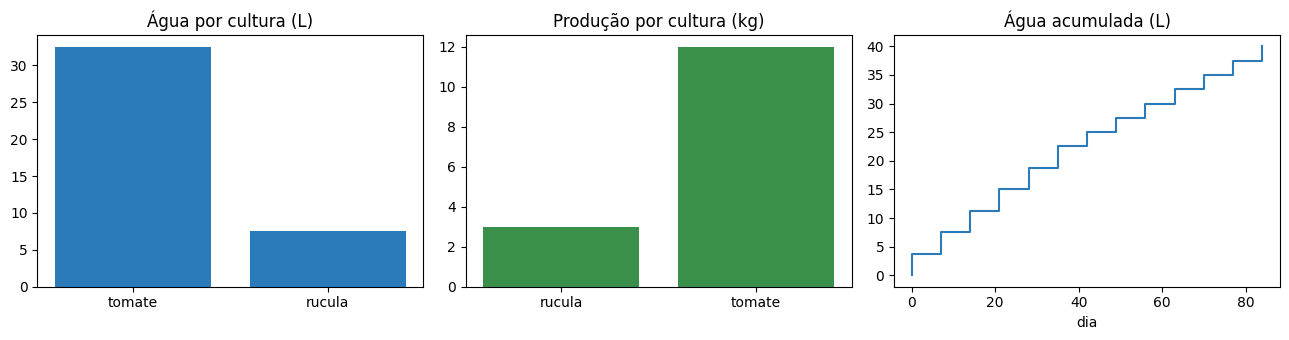

In [20]:
import matplotlib.pyplot as plt

def grafico_horta(horta):
    fig, eixos = plt.subplots(1, 3, figsize=(13, 3.5))
    for eixo, dados, titulo, cor in ((eixos[0], horta.agua, "Água por cultura (L)", "#2b7bba"),
                                     (eixos[1], horta.colheitas, "Produção por cultura (kg)", "#3a8f4b")):
        eixo.bar(list(dados), list(dados.values()), color=cor)
        eixo.set_title(titulo)
    dias, litros = zip(*horta.linha_do_tempo)
    eixos[2].step(dias, litros, where="post", color="#2b7bba")
    eixos[2].set_title("Água acumulada (L)")
    eixos[2].set_xlabel("dia")
    fig.tight_layout()
    plt.show()

grafico_horta(compilar(EXEMPLO_MISTA).resultado.horta)

## Passo 8 — Testes automáticos (R8)

In [21]:

CASOS = [
    ("válido: alface", EXEMPLO_ALFACE, None, "colhidos 3.60 kg de alface"),
    ("válido: horta mista", EXEMPLO_MISTA, None, "colhidos 12.00 kg de tomate"),
    ("válido: funções e recursão", EXEMPLO_FUNCOES, None, "colhidos 1.00 kg de manjericao"),
    ("válido: precedência", "mostrar 2 + 3 * 4 - 1;", None, "13"),
    ("válido: escopo e sombra", "inteiro x = 1; se (verdadeiro) { inteiro x = 2; mostrar x; } mostrar x;", None, "🗨️  1"),
    ("válido: coerção", "decimal d = 3; mostrar d;", None, "3.0"),
    ("válido: 1, 1.0 e verdadeiro", "mostrar 1, 1.0, verdadeiro;", None, "1 1.0 verdadeiro"),
    ("léxico: aspas simples", "plantar 'alface', 1;", "léxico", "aspas duplas"),
    ("léxico: símbolo @", "inteiro @x = 1;", "léxico", "caractere inesperado"),
    ("sintático: falta ;", "inteiro x = 1 mostrar x;", "sintático", "';'"),
    ("sintático: bloco aberto", "se (verdadeiro) { mostrar 1;", "sintático", "'}'"),
    ("semântico: não declarado", "inteiro total = 1; mostrar totl;", "semântico", "você quis dizer 'total'"),
    ("semântico: tipos", 'mostrar 1 + "a";', "semântico", "não se aplica"),
    ("semântico: água demais", 'plantar "alface", 1; regar "alface", 11;', "semântico", "até 10"),
    ("semântico: mudas negativas", 'plantar "alface", -3;', "semântico", "maior que 0"),
    ("semântico: argumentos", "funcao inteiro f(inteiro a) { retornar a; } mostrar f(1, 2);", "semântico", "espera 1"),
    ("execução: divisão por zero", ERROS_EXECUCAO["divisão por zero"], "de execução", "divisão por zero"),
    ("execução: divisão constante", "mostrar 1 / 0;", "de execução", "divisão por zero"),
    ("execução: laço infinito", ERROS_EXECUCAO["laço infinito"], "de execução", "laço infinito"),
    ("execução: recursão infinita", "funcao inteiro f(inteiro n) { retornar f(n); } mostrar f(1);", "de execução", "pilha"),
    ("execução: cedo demais", ERROS_EXECUCAO["colheita antes da hora"], "de execução", "antes da hora"),
]

def rodar_testes():
    passou = 0
    for nome, prog, fase, trecho in CASOS:
        c = compilar(prog)
        if fase is None:
            ok = c.erro is None and trecho in c.resultado.saida
        else:
            ok = c.erro is not None and c.erro.fase == fase and trecho in str(c.erro)
        if c.tac is not None:
            a, d = executar_tac(c.tac), executar_tac(c.otimizado)
            if not (a.erro and "laço infinito" in a.erro.msg):
                m = executar_assembly(c.assembly)
                ok = ok and a.saida == d.saida == m.saida and str(a.erro) == str(d.erro)
        passou += ok
        print("✅" if ok else "❌", nome, "" if ok else f"-> {c.erro}")
    print(f"\n{passou}/{len(CASOS)} testes passaram")
    assert passou == len(CASOS)

rodar_testes()

✅ válido: alface 
✅ válido: horta mista 
✅ válido: funções e recursão 
✅ válido: precedência 
✅ válido: escopo e sombra 
✅ válido: coerção 
✅ válido: 1, 1.0 e verdadeiro 
✅ léxico: aspas simples 
✅ léxico: símbolo @ 
✅ sintático: falta ; 
✅ sintático: bloco aberto 
✅ semântico: não declarado 
✅ semântico: tipos 
✅ semântico: água demais 
✅ semântico: mudas negativas 
✅ semântico: argumentos 
✅ execução: divisão por zero 
✅ execução: divisão constante 
✅ execução: laço infinito 
✅ execução: recursão infinita 
✅ execução: cedo demais 

21/21 testes passaram


## Passo 9 — HortaScript Studio (R9)
Escolha um exemplo ou escreva seu programa e clique em **Compilar e executar**.

In [22]:
import ipywidgets as widgets
from IPython.display import display

EXEMPLOS = {"Alface": EXEMPLO_ALFACE, "Horta mista": EXEMPLO_MISTA, "Funções": EXEMPLO_FUNCOES,
            "Erro semântico": 'plantar "alfaci", 3;', "Erro de execução": ERROS_EXECUCAO["colheita antes da hora"]}
VISOES = ["Execução", "Tokens", "AST", "TAC", "Otimizado", "Assembly", "Gráfico"]

escolha = widgets.Dropdown(options=list(EXEMPLOS), description="Exemplo:")
editor = widgets.Textarea(value=EXEMPLOS[escolha.value], layout=widgets.Layout(width="100%", height="300px"))
botao = widgets.Button(description="Compilar e executar", button_style="success")
saidas = [widgets.Output() for _ in VISOES]
abas = widgets.Tab(children=saidas)
for n, titulo in enumerate(VISOES):
    abas.set_title(n, titulo)

def ao_escolher(mudanca):
    editor.value = EXEMPLOS[mudanca["new"]]

def ao_clicar(_):
    c = compilar(editor.value)
    acoes = [
        lambda: relatorio(c),
        lambda: mostrar_tokens(editor.value),
        lambda: mostrar_ast(c.ast),
        lambda: mostrar_tac(c.tac),
        lambda: mostrar_tac(c.otimizado),
        lambda: mostrar_assembly(c.assembly),
        lambda: grafico_horta(c.resultado.horta),
    ]
    precisa = [c, c.tokens, c.ast, c.tac, c.otimizado, c.assembly, c.resultado]
    for saida, acao, dado in zip(saidas, acoes, precisa):
        saida.clear_output()
        with saida:
            if dado is None:
                print("Fase não alcançada:", c.erro)
            else:
                acao()

escolha.observe(ao_escolher, names="value")
botao.on_click(ao_clicar)
display(widgets.VBox([escolha, editor, botao, abas]))
ao_clicar(None)